In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species")

print("Dataset shape:", X.shape)
display(X.head())

print("\\nTarget classes:", iris.target_names)
print("\\nClass distribution:")
print(y.value_counts().sort_index())

Dataset shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


\nTarget classes: ['setosa' 'versicolor' 'virginica']
\nClass distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64


In [3]:
print("Feature names:")
print(X.columns.tolist())

print("\\nDataset summary:")
display(X.describe())

print("\\nMissing values:", X.isnull().sum().sum())

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
\nDataset summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


\nMissing values: 0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [5]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


In [6]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": iris.target_names[y_test.to_numpy()],
    "Predicted": iris.target_names[y_pred]
})

display(comparison.head(10))

,Actual,Predicted
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [7]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=iris.target_names,
    zero_division=0
))

Accuracy: 0.9667
\nClassification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



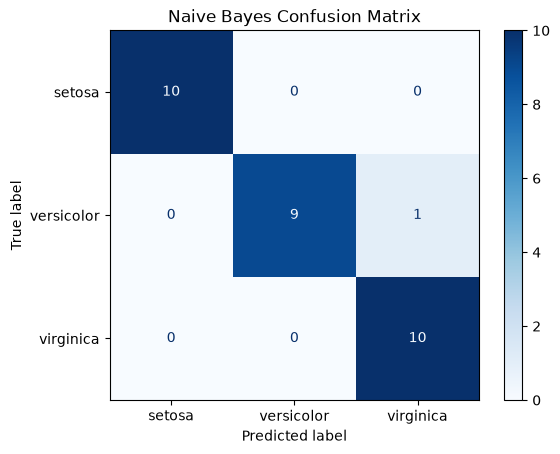

In [8]:
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

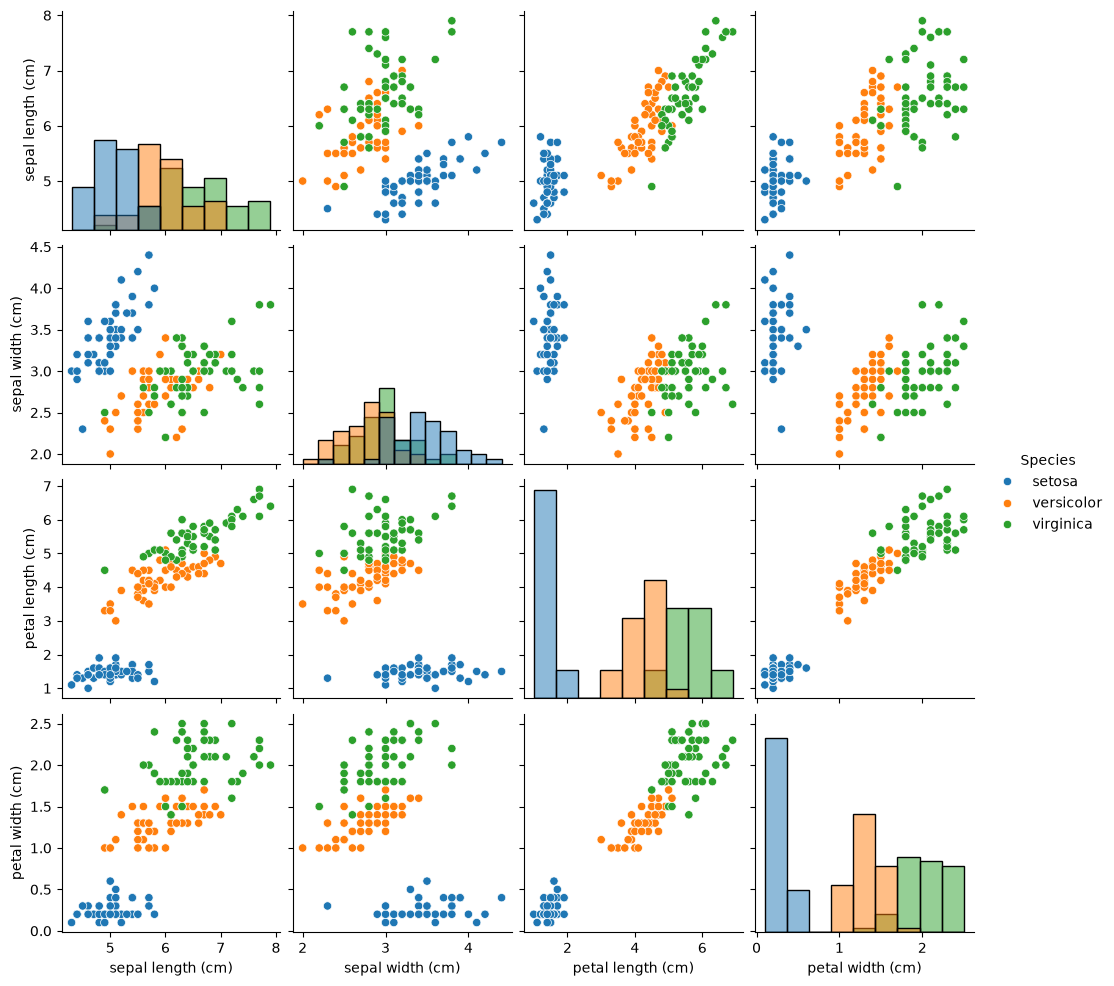

In [9]:
plot_data = X.copy()
plot_data["Species"] = iris.target_names[y.to_numpy()]

sns.pairplot(plot_data, hue="Species", diag_kind="hist")
plt.show()

In [10]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

predicted_class = model.predict(new_flower)[0]
predicted_probabilities = model.predict_proba(new_flower)[0]

print("Predicted species:", iris.target_names[predicted_class])
print("\\nClass probabilities:")
for species, probability in zip(iris.target_names, predicted_probabilities):
    print(f"{species}: {probability:.4f}")

Predicted species: setosa
\nClass probabilities:
setosa: 1.0000
versicolor: 0.0000
virginica: 0.0000
